In [ ]:
%matplotlib inline

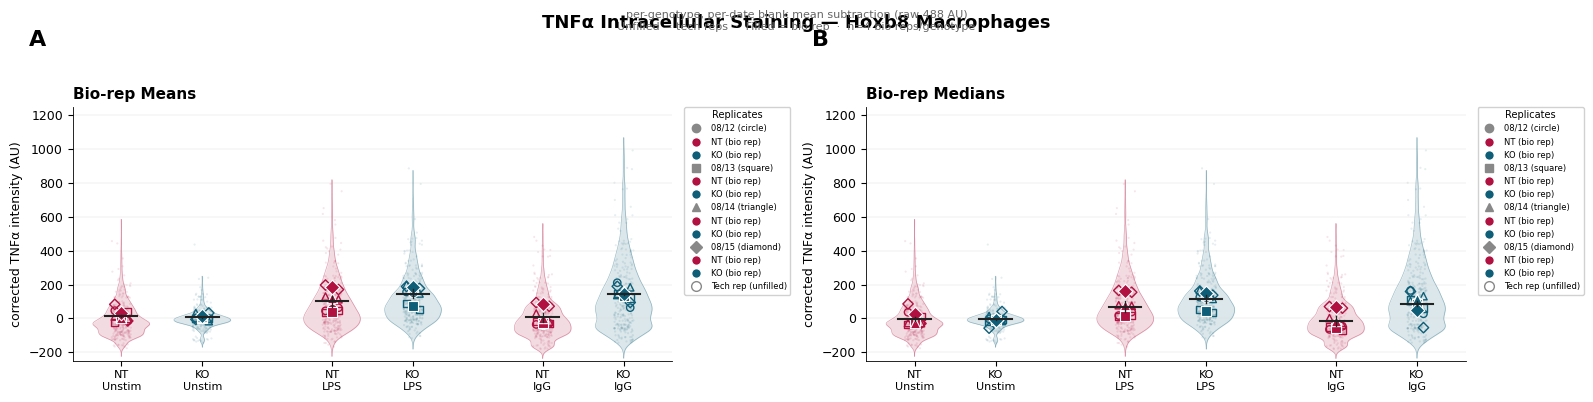

Saved: fig1_violins.pdf

 MEANS (AU)   
Date	NT Unstim	KO Unstim	NT LPS	KO LPS	NT IgG	KO IgG
20260812	15.40	-0.24	53.60	155.70	-32.63	136.98
20260813	8.60	-0.01	40.46	71.18	-25.58	132.69
20260814	3.49	7.73	121.05	172.95	4.71	160.76
20260815	33.83	13.13	183.75	182.85	82.42	141.54

  MEDIANS (AU)   
Date	NT Unstim	KO Unstim	NT LPS	KO LPS	NT IgG	KO IgG
20260812	2.00	-4.37	27.26	125.16	-55.93	96.03
20260813	-13.90	-11.60	13.71	43.65	-59.30	85.80
20260814	-27.43	-0.51	76.08	140.97	-18.30	116.99
20260815	27.61	-8.71	159.54	149.31	64.99	52.04


In [13]:
#  not in fig
#  Violin Superplots (Mean & Median)
# normalization: per-genotype, per-date blank mean subtraction on raw intensities

import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
import warnings
warnings.filterwarnings('ignore')

#    Data
try:
    _dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _dir = os.getcwd()
df = pd.read_csv(os.path.join(_dir, 'tnfa_data_iso_subtracted.csv'))
dates = sorted(df['date'].unique())
date_labels = {20260812: '08/12', 20260813: '08/13',
               20260814: '08/14', 20260815: '08/15'}

#    Method C: per-genotype, per-date blank mean subtraction
blank_means = {}
for g in ['nt', 'ko']:
    for d in dates:
        s = df[(df['genotype'] == g) & (df['treatment'] == 'blank') & (df['date'] == d)]['mean_intensity_488']
        if len(s) > 0:
            blank_means[(g, d)] = s.mean()

df['method_c'] = df.apply(lambda r: r['mean_intensity_488'] - blank_means[(r['genotype'], r['date'])], axis=1)

#    Colors: NT = indianred, KO = dark blue
geno_colors = {'nt': '#B01141', 'ko': '#0F5E78'}

#    Marker shapes per date
date_markers = {20260812: 'o', 20260813: 's',
                20260814: '^', 20260815: 'D'}
date_marker_labels = {20260812: '08/12 (circle)', 20260813: '08/13 (square)',
                      20260814: '08/14 (triangle)', 20260815: '08/15 (diamond)'}

#    Group order
group_order = [
    ('nt', 'blank'), ('ko', 'blank'),
    ('nt', 'lps'),   ('ko', 'lps'),
    ('nt', 'igg'),   ('ko', 'igg'),
]
group_label_map = {
    ('nt', 'blank'): 'NT\nUnstim', ('ko', 'blank'): 'KO\nUnstim',
    ('nt', 'lps'):   'NT\nLPS',    ('ko', 'lps'):   'KO\nLPS',
    ('nt', 'igg'):   'NT\nIgG',    ('ko', 'igg'):   'KO\nIgG',
}

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 9,
    'axes.linewidth': 0.6,
})

#    X positions
x_positions = {}
x_ticks = []
x_ticklabels = []
xp = 0
for i, (geno, treat) in enumerate(group_order):
    x_positions[(geno, treat)] = xp
    x_ticks.append(xp)
    x_ticklabels.append(group_label_map[(geno, treat)])
    if i % 2 == 1 and i < len(group_order) - 1:
        xp += 1.6
    else:
        xp += 1.0


#    Helper functions
def compute_tech_rep_stat(df, stat='mean'):
    records = []
    for geno, treat in group_order:
        for date in dates:
            sub = df[(df['genotype'] == geno) & (df['treatment'] == treat) & (df['date'] == date)]
            for tr in sorted(sub['tech_rep'].unique()):
                tr_sub = sub[sub['tech_rep'] == tr]['method_c']
                val = tr_sub.mean() if stat == 'mean' else tr_sub.median()
                records.append({'genotype': geno, 'treatment': treat, 'date': date,
                                'tech_rep': int(tr), 'value': val})
    return pd.DataFrame(records)


def compute_bio_rep_stat(df, stat='mean'):
    tr_df = compute_tech_rep_stat(df, stat)
    records = []
    for geno, treat in group_order:
        for date in dates:
            sub = tr_df[(tr_df['genotype'] == geno) & (tr_df['treatment'] == treat) & (tr_df['date'] == date)]
            if len(sub) == 0: continue
            records.append({'genotype': geno, 'treatment': treat, 'date': date,
                            'value': sub['value'].mean()})
    return pd.DataFrame(records)


def kde_violin(data, bw=0.15):
    data = data[np.isfinite(data)]
    if len(data) < 5: return None, None
    try:
        kde = gaussian_kde(data, bw_method=bw)
        top = np.percentile(data, 99.5)
        bottom = np.percentile(data, 0.5)
        pad = (top - bottom) * 0.08
        x_grid = np.linspace(bottom - pad, top, 200)
        return x_grid, kde(x_grid)
    except:
        return None, None


def plot_dots(ax, tr_data, br_data, group_keys, x_map):
    """Plot tech rep (unfilled) and bio rep (filled) dots with date-based markers."""
    for date in dates:
        for geno, treat in group_keys:
            xc = x_map[(geno, treat)] if isinstance(x_map, dict) else x_map[group_keys.index((geno, treat))]
            color = geno_colors[geno]
            marker = date_markers[date]
            trs = tr_data[(tr_data['genotype'] == geno) & (tr_data['treatment'] == treat) &
                          (tr_data['date'] == date)]
            for _, row in trs.iterrows():
                offset = -0.08 if row['tech_rep'] == 1 else 0.08
                ax.scatter(xc + offset, row['value'], s=28, marker=marker,
                           facecolors='none', edgecolors=color,
                           linewidths=1.0, zorder=4)

    for date in dates:
        for geno, treat in group_keys:
            xc = x_map[(geno, treat)] if isinstance(x_map, dict) else x_map[group_keys.index((geno, treat))]
            marker = date_markers[date]
            row = br_data[(br_data['genotype'] == geno) & (br_data['treatment'] == treat) &
                          (br_data['date'] == date)]
            if len(row) > 0:
                ax.scatter(xc, row['value'].values[0], s=55, marker=marker,
                           color=geno_colors[geno], edgecolors='white',
                           linewidths=0.8, zorder=5)

    for geno, treat in group_keys:
        xc = x_map[(geno, treat)] if isinstance(x_map, dict) else x_map[group_keys.index((geno, treat))]
        vals = br_data[(br_data['genotype'] == geno) & (br_data['treatment'] == treat)]['value'].values
        if len(vals) > 0:
            m = np.mean(vals)
            sem = np.std(vals, ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
            ax.plot([xc - 0.2, xc + 0.2], [m, m], color='#222', linewidth=1.5, zorder=6)
            ax.plot([xc, xc], [m - sem, m + sem], color='#222', linewidth=1.0, zorder=6)


def make_legend(ax, outside=False):
    handles = []
    for d in dates:
        handles.append(Line2D([0], [0], marker=date_markers[d], color='w',
                              markerfacecolor='#888', markeredgecolor='#888',
                              markersize=6, label=date_marker_labels[d]))
        handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='#B01141',
                              markersize=7, label='NT (bio rep)'))
        handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='#0F5E78',
                              markersize=7, label='KO (bio rep)'))
    handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
                          markeredgecolor='#888', markersize=7, label='Tech rep (unfilled)'))
    if outside:
        ax.legend(handles=handles, fontsize=6, loc='upper left',
                  bbox_to_anchor=(1.02, 1), borderaxespad=0,
                  title='Replicates', title_fontsize=7, framealpha=0.9, edgecolor='#ccc')
    else:
        ax.legend(handles=handles, fontsize=6, loc='upper right',
                  title='Replicates', title_fontsize=7, framealpha=0.9, edgecolor='#ccc')


# ═══════════════════════════════════════════
#  FIGURE 1: Violin Superplots (Mean & Median)
# ═══════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
fig.suptitle('TNFα Intracellular Staining — Hoxb8 Macrophages',
             fontsize=13, fontweight='bold', y=0.98)
fig.text(0.5, 0.94,
         'per-genotype, per-date blank mean subtraction (raw 488 AU)\n'
         'Unfilled = tech reps  ·  Filled = bio rep  ·  '
         'n=4 bio reps/genotype',
         ha='center', fontsize=8, color='#666')

for panel_idx, (stat_name, br_data, tr_data) in enumerate([
    ('Mean', compute_bio_rep_stat(df, 'mean'), compute_tech_rep_stat(df, 'mean')),
    ('Median', compute_bio_rep_stat(df, 'median'), compute_tech_rep_stat(df, 'median')),
]):
    ax = axes[panel_idx]

    # Violins
    violin_width = 0.35
    for geno, treat in group_order:
        xc = x_positions[(geno, treat)]
        color = geno_colors[geno]
        cells = df[(df['genotype'] == geno) & (df['treatment'] == treat)]['method_c'].values
        y_grid, density = kde_violin(cells)
        if y_grid is not None:
            dn = density / density.max() * violin_width
            ax.fill_betweenx(y_grid, xc - dn, xc + dn, alpha=0.15,
                             color=color, linewidth=0)
            ax.plot(xc - dn, y_grid, color=color, linewidth=0.5, alpha=0.4)
            ax.plot(xc + dn, y_grid, color=color, linewidth=0.5, alpha=0.4)

    # Cell scatter (subsample)
    np.random.seed(42)
    for geno, treat in group_order:
        xc = x_positions[(geno, treat)]
        color = geno_colors[geno]
        cells = df[(df['genotype'] == geno) & (df['treatment'] == treat)]['method_c'].values
        cs = np.random.choice(cells, min(300, len(cells)), replace=False) if len(cells) > 0 else cells
        jitter = np.random.uniform(-0.12, 0.12, len(cs))
        ax.scatter(xc + jitter, cs, s=2.5, alpha=0.1, color=color,
                   edgecolors='none', zorder=1, rasterized=True)

    plot_dots(ax, tr_data, br_data, group_order, x_positions)

    ax.set_ylim(-250, 1250)
    ax.set_xlim(x_ticks[0] - 0.6, x_ticks[-1] + 0.6)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_ticklabels, fontsize=8)
    ax.set_ylabel('corrected TNFα intensity (AU)', fontsize=9)
    ax.set_title(f'Bio-rep {stat_name}s', fontsize=11, fontweight='600', loc='left')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linewidth=0.3, color='#ddd')
    make_legend(ax, outside=True)

fig.text(0.02, 0.90, 'A', fontsize=16, fontweight='bold')
fig.text(0.51, 0.90, 'B', fontsize=16, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(os.path.join(_dir, 'fig1_violins.pdf'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig1_violins.pdf')

#    Print bio rep means for Prism import
print('\n MEANS (AU)   ')
print('Date\t' + '\t'.join(group_label_map[g].replace('\n',' ') for g in group_order))
br_mean = compute_bio_rep_stat(df, 'mean')
for date in dates:
    vals = []
    for geno, treat in group_order:
        row = br_mean[(br_mean['genotype']==geno) & (br_mean['treatment']==treat) & (br_mean['date']==date)]
        vals.append(f'{row["value"].values[0]:.2f}' if len(row) > 0 else '')
    print(f'{date}\t' + '\t'.join(vals))

print('\n  MEDIANS (AU)   ')
print('Date\t' + '\t'.join(group_label_map[g].replace('\n',' ') for g in group_order))
br_median = compute_bio_rep_stat(df, 'median')
for date in dates:
    vals = []
    for geno, treat in group_order:
        row = br_median[(br_median['genotype']==geno) & (br_median['treatment']==treat) & (br_median['date']==date)]
        vals.append(f'{row["value"].values[0]:.2f}' if len(row) > 0 else '')
    print(f'{date}\t' + '\t'.join(vals))


Per-genotype isotype means used:
  NT: 504.98 AU
  KO: 485.21 AU


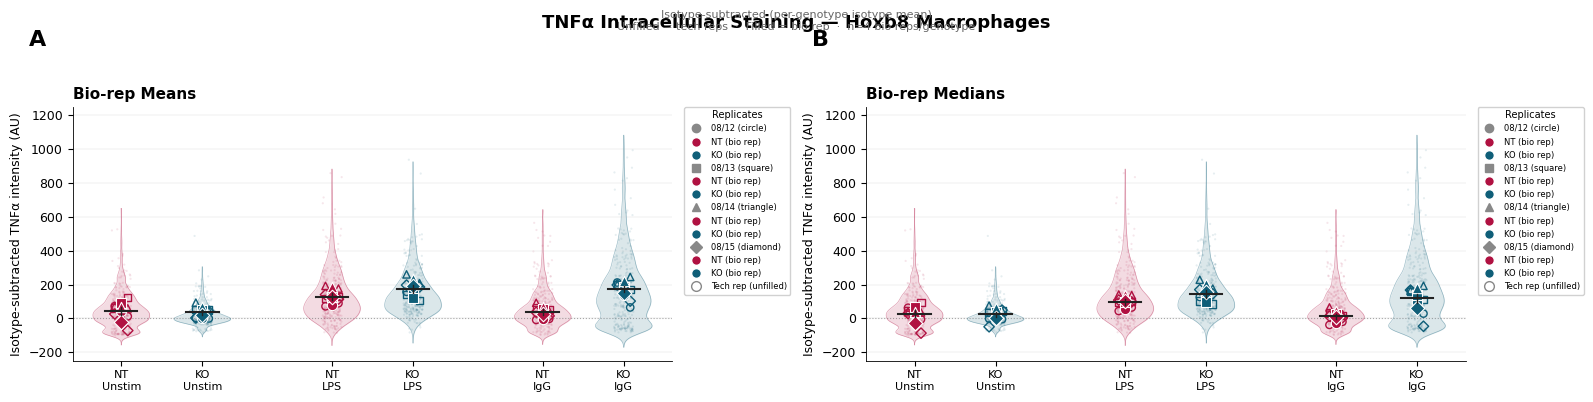

Saved: fig2_violins_isosub.pdf

  Isotype-Subtracted Bio Rep MEANS 
Date	NT Unstim	KO Unstim	NT LPS	KO LPS	NT IgG	KO IgG
20260812	42.05	0.97	80.25	156.91	-5.99	138.19
20260813	92.06	50.92	123.93	122.11	57.89	183.63
20260814	66.67	68.91	184.24	234.13	67.89	221.94
20260815	-23.13	21.36	126.79	191.08	25.46	149.77

  Isotype-Subtracted Bio Rep MEDIANS  
Date	NT Unstim	KO Unstim	NT LPS	KO LPS	NT IgG	KO IgG
20260812	28.65	-3.16	53.91	126.36	-29.28	97.24
20260813	69.56	39.33	97.17	94.59	24.16	136.74
20260814	35.75	60.67	139.26	202.15	44.88	178.17
20260815	-29.35	-0.48	102.57	157.54	8.03	60.27


In [16]:
# IN FIGURE
# Violin Superplots — Isotype-Subtracted per Genotype
# Normalization: subtract per-genotype isotype mean from raw mean_intensity_488
# NT isotype mean = 504.98 AU (well F06, n=526)
# KO isotype mean = 485.21 AU (wells F02-F04, n=1669)

iso_mean = {'nt': 504.98, 'ko': 485.21}
df['iso_sub'] = df.apply(lambda r: r['mean_intensity_488'] - iso_mean[r['genotype']], axis=1)

print('Per-genotype isotype means used:')
for g in ['nt', 'ko']:
    print(f'  {g.upper()}: {iso_mean[g]:.2f} AU')


#   Local helper functions for iso_sub column
def compute_tech_rep_stat_iso(df, stat='mean'):
    records = []
    for geno, treat in group_order:
        for date in dates:
            sub = df[(df['genotype'] == geno) & (df['treatment'] == treat) & (df['date'] == date)]
            for tr in sorted(sub['tech_rep'].unique()):
                tr_sub = sub[sub['tech_rep'] == tr]['iso_sub']
                val = tr_sub.mean() if stat == 'mean' else tr_sub.median()
                records.append({'genotype': geno, 'treatment': treat, 'date': date,
                                'tech_rep': int(tr), 'value': val})
    return pd.DataFrame(records)


def compute_bio_rep_stat_iso(df, stat='mean'):
    tr_df = compute_tech_rep_stat_iso(df, stat)
    records = []
    for geno, treat in group_order:
        for date in dates:
            sub = tr_df[(tr_df['genotype'] == geno) & (tr_df['treatment'] == treat) & (tr_df['date'] == date)]
            if len(sub) == 0: continue
            records.append({'genotype': geno, 'treatment': treat, 'date': date,
                            'value': sub['value'].mean()})
    return pd.DataFrame(records)


# ═══════════════════════════════════════════
#  FIGURE 2: Violin Superplots — Isotype-Subtracted
# ═══════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
fig.suptitle('TNFα Intracellular Staining — Hoxb8 Macrophages',
             fontsize=13, fontweight='bold', y=0.98)
fig.text(0.5, 0.94,
         'Isotype-subtracted (per-genotype isotype mean)\n'
         'Unfilled = tech reps  ·  Filled = bio rep  ·  '
         'n=4 bio reps/genotype',
         ha='center', fontsize=8, color='#666')

for panel_idx, (stat_name, br_data, tr_data) in enumerate([
    ('Mean', compute_bio_rep_stat_iso(df, 'mean'), compute_tech_rep_stat_iso(df, 'mean')),
    ('Median', compute_bio_rep_stat_iso(df, 'median'), compute_tech_rep_stat_iso(df, 'median')),
]):
    ax = axes[panel_idx]

    # Violins
    violin_width = 0.35
    for geno, treat in group_order:
        xc = x_positions[(geno, treat)]
        color = geno_colors[geno]
        cells = df[(df['genotype'] == geno) & (df['treatment'] == treat)]['iso_sub'].values
        y_grid, density = kde_violin(cells)
        if y_grid is not None:
            dn = density / density.max() * violin_width
            ax.fill_betweenx(y_grid, xc - dn, xc + dn, alpha=0.15,
                             color=color, linewidth=0)
            ax.plot(xc - dn, y_grid, color=color, linewidth=0.5, alpha=0.4)
            ax.plot(xc + dn, y_grid, color=color, linewidth=0.5, alpha=0.4)

    # Cell scatter (subsample)
    np.random.seed(42)
    for geno, treat in group_order:
        xc = x_positions[(geno, treat)]
        color = geno_colors[geno]
        cells = df[(df['genotype'] == geno) & (df['treatment'] == treat)]['iso_sub'].values
        cs = np.random.choice(cells, min(300, len(cells)), replace=False) if len(cells) > 0 else cells
        jitter = np.random.uniform(-0.12, 0.12, len(cs))
        ax.scatter(xc + jitter, cs, s=2.5, alpha=0.1, color=color,
                   edgecolors='none', zorder=1, rasterized=True)

    plot_dots(ax, tr_data, br_data, group_order, x_positions)

    ax.axhline(0, color='#999', ls=':', lw=0.8, zorder=0)
    ax.set_ylim(-250, 1250)
    ax.set_xlim(x_ticks[0] - 0.6, x_ticks[-1] + 0.6)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_ticklabels, fontsize=8)
    ax.set_ylabel('Isotype-subtracted TNFα intensity (AU)', fontsize=9)
    ax.set_title(f'Bio-rep {stat_name}s', fontsize=11, fontweight='600', loc='left')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linewidth=0.3, color='#ddd')
    make_legend(ax, outside=True)

fig.text(0.02, 0.90, 'A', fontsize=16, fontweight='bold')
fig.text(0.51, 0.90, 'B', fontsize=16, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(os.path.join(_dir, 'fig2_violins_isosub.pdf'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig2_violins_isosub.pdf')

# Print bio rep values
print('\n  Isotype-Subtracted Bio Rep MEANS ')
print('Date\t' + '\t'.join(group_label_map[g].replace('\n',' ') for g in group_order))
br_mean = compute_bio_rep_stat_iso(df, 'mean')
for date in dates:
    vals = []
    for geno, treat in group_order:
        row = br_mean[(br_mean['genotype']==geno) & (br_mean['treatment']==treat) & (br_mean['date']==date)]
        vals.append(f'{row["value"].values[0]:.2f}' if len(row) > 0 else '')
    print(f'{date}\t' + '\t'.join(vals))

print('\n  Isotype-Subtracted Bio Rep MEDIANS  ')
print('Date\t' + '\t'.join(group_label_map[g].replace('\n',' ') for g in group_order))
br_median = compute_bio_rep_stat_iso(df, 'median')
for date in dates:
    vals = []
    for geno, treat in group_order:
        row = br_median[(br_median['genotype']==geno) & (br_median['treatment']==treat) & (br_median['date']==date)]
        vals.append(f'{row["value"].values[0]:.2f}' if len(row) > 0 else '')
    print(f'{date}\t' + '\t'.join(vals))

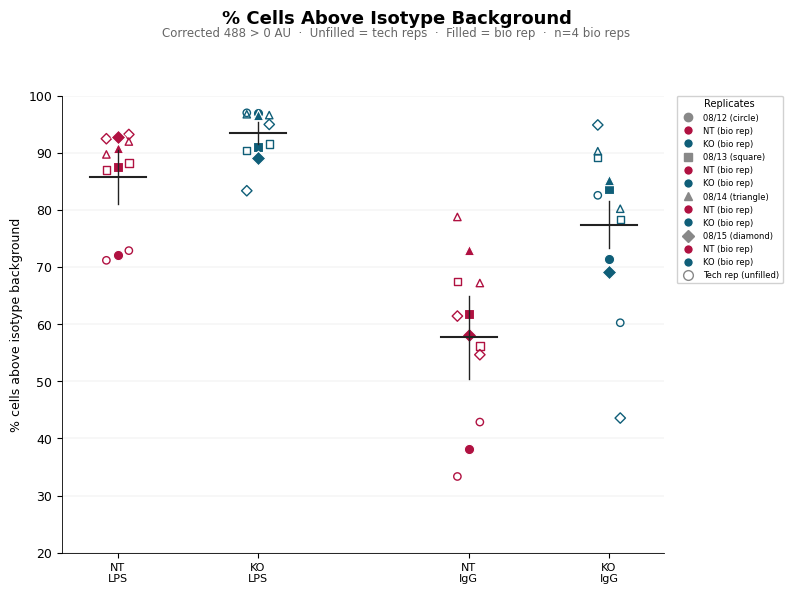

Saved: fig2_pct_above_bg.pdf

  Cell 3: Bio Rep % Cells Above Isotype Background (>0 AU)  
Date	NT LPS	KO LPS	NT IgG	KO IgG
20260812	72.01	96.97	38.10	71.39
20260813	87.57	90.96	61.82	83.71
20260814	90.82	96.64	72.97	85.22
20260815	92.81	89.14	58.02	69.20


In [17]:
#  not in fig
# % Cells Above Isotype Background (>0 AU)
# Uses isotype-corrected values (corrected_488) for absolute threshold
# Layout: NT LPS, KO LPS, [gap], NT IgG, KO IgG

cell2_groups = [
    ('nt', 'lps'), ('ko', 'lps'),
    ('nt', 'igg'), ('ko', 'igg'),
]
cell2_labels = ['NT\nLPS', 'KO\nLPS', 'NT\nIgG', 'KO\nIgG']
cell2_x = [0, 1, 2.5, 3.5]

fig, ax = plt.subplots(figsize=(8, 6))
fig.suptitle('% Cells Above Isotype Background',
             fontsize=13, fontweight='bold', y=0.98)
fig.text(0.5, 0.935,
         'Corrected 488 > 0 AU  ·  Unfilled = tech reps  ·  Filled = bio rep  ·  '
         'n=4 bio reps',
         ha='center', fontsize=8.5, color='#666')

# Compute % cells > 0 AU per tech rep and bio rep
tr_above_records = []
br_above_records = []
for geno, treat in cell2_groups:
    for date in dates:
        sub = df[(df['genotype'] == geno) & (df['treatment'] == treat) & (df['date'] == date)]
        if len(sub) == 0: continue
        tr_pcts = []
        for tr in sorted(sub['tech_rep'].unique()):
            tr_sub = sub[sub['tech_rep'] == tr]['corrected_488']
            pct = (tr_sub > 0).mean() * 100
            tr_above_records.append({'genotype': geno, 'treatment': treat, 'date': date,
                                     'tech_rep': int(tr), 'value': pct})
            tr_pcts.append(pct)
        br_above_records.append({'genotype': geno, 'treatment': treat, 'date': date,
                                  'value': np.mean(tr_pcts)})

tr_above = pd.DataFrame(tr_above_records)
br_above = pd.DataFrame(br_above_records)

# Tech rep dots (unfilled)
for date in dates:
    for gi, (geno, treat) in enumerate(cell2_groups):
        xc = cell2_x[gi]
        color = geno_colors[geno]
        marker = date_markers[date]
        trs = tr_above[(tr_above['genotype'] == geno) & (tr_above['treatment'] == treat) &
                        (tr_above['date'] == date)]
        for _, row in trs.iterrows():
            offset = -0.08 if row['tech_rep'] == 1 else 0.08
            ax.scatter(xc + offset, row['value'], s=28, marker=marker,
                       facecolors='none', edgecolors=color,
                       linewidths=1.0, zorder=4)

# Bio rep dots (filled)
for date in dates:
    for gi, (geno, treat) in enumerate(cell2_groups):
        xc = cell2_x[gi]
        marker = date_markers[date]
        row = br_above[(br_above['genotype'] == geno) & (br_above['treatment'] == treat) &
                        (br_above['date'] == date)]
        if len(row) > 0:
            ax.scatter(xc, row['value'].values[0], s=55, marker=marker,
                       color=geno_colors[geno], edgecolors='white',
                       linewidths=0.8, zorder=5)

# Mean ± SEM bars
for gi, (geno, treat) in enumerate(cell2_groups):
    xc = cell2_x[gi]
    vals = br_above[(br_above['genotype'] == geno) & (br_above['treatment'] == treat)]['value'].values
    if len(vals) > 0:
        m = np.mean(vals)
        sem = np.std(vals, ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
        ax.plot([xc - 0.2, xc + 0.2], [m, m], color='#222', linewidth=1.5, zorder=6)
        ax.plot([xc, xc], [m - sem, m + sem], color='#222', linewidth=1.0, zorder=6)

ax.set_xticks(cell2_x)
ax.set_xticklabels(cell2_labels, fontsize=8)
ax.set_ylabel('% cells above isotype background', fontsize=9)
ax.set_ylim(20, 100)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linewidth=0.3, color='#ddd')
make_legend(ax, outside=True)

fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig(os.path.join(_dir, 'fig3_pct_above_bg.pdf'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig2_pct_above_bg.pdf')

#   Print bio rep % above background for Prism import
cell2_label_names = {('nt','lps'): 'NT LPS', ('ko','lps'): 'KO LPS',
                     ('nt','igg'): 'NT IgG', ('ko','igg'): 'KO IgG'}
print('\n  Cell 3: Bio Rep % Cells Above Isotype Background (>0 AU)  ')
print('Date\t' + '\t'.join(cell2_label_names[g] for g in cell2_groups))
for date in dates:
    vals = []
    for geno, treat in cell2_groups:
        row = br_above[(br_above['genotype']==geno) & (br_above['treatment']==treat) & (br_above['date']==date)]
        vals.append(f'{row["value"].values[0]:.2f}' if len(row) > 0 else '')
    print(f'{date}\t' + '\t'.join(vals))